<a href="https://colab.research.google.com/github/hombremono873/Cuadernos_colab/blob/main/Omar_Torres_Diego_Roa_Entregable_dos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Entrega 2**

### **Universidad Santo Tomás**
**Especialización / Maestría:** Análisis de datos y sistemas inteligentes  

---

* **Fecha:** 25 de octubre del 2026
* **Estudiantes:**
  * Omar Alberto Torres
  * Diego Alejandro Roa Lara
* **Docente:** Gerardo Humberto Valencia Rivera

## **Carga de librerías**

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn.linear_model
from utils import cargar_dataset, perturbar_datos_con_tope
import utils

#Librerías para fase 2
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

import sklearn.neighbors
from sklearn.tree import DecisionTreeRegressor

from sklearn.model_selection import GridSearchCV
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OneHotEncoder

## **1. Carga y perturbacion**

**Que hace:** Carga California Housing, el docente altera 3 columnas al azar con ruido y NaN en el 20 por ciento de sus filas, y ordena el dataset por median_income.

**Errores inducidos:**
- Ordenar antes de dividir sesga los conjuntos y produce R2 negativos.
- Los NaN de median_income quedan todos en prueba.
- Se descarta ocean_proximity, que es util.


✅ Dataset cargado con éxito desde GITHUB. Registros: 20640
--- REPORTE DE PERTURBACIÓN (Tope Máx: 20.0%) ---
  • Columna 'median_income': 4128 filas alteradas (2477 con ruido, 1651 convertidas a NaN)
  • Columna 'latitude': 4128 filas alteradas (2477 con ruido, 1651 convertidas a NaN)
  • Columna 'population': 4128 filas alteradas (2477 con ruido, 1651 convertidas a NaN)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.325200,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.301400,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,NaN,177.0,7.257400,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.107717,341300.0,NEAR BAY
4,-122.25,NaN,52.0,1627.0,280.0,565.0,259.0,3.846200,342200.0,NEAR BAY


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            18989 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          18989 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       18989 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


np.int64(5160)

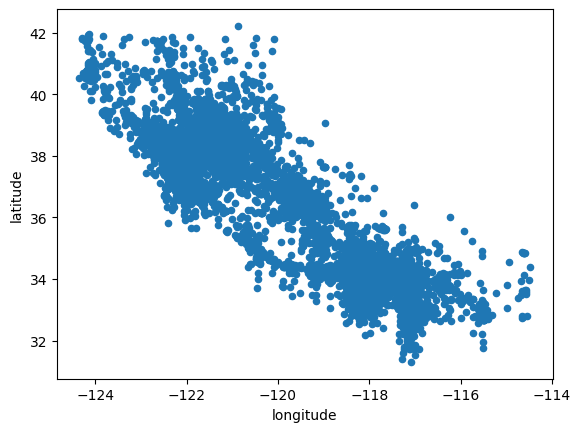

In [3]:
utils.np = np

url_housing = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
dataset_housing = cargar_dataset(
    fuente="github", ruta_o_nombre=url_housing
)

## Test de fuga de datos ##
X_perturbado, cols_afectadas = perturbar_datos_con_tope(
    dataset_housing,
    num_features_to_perturb=3,  # Elige 3 características al azar
    max_budget_per_feature=0.20,  # Ninguna columna supera el 20% de afectación
    noise_magnitude=0.25,  # Ruido del 25% de la desviación estándar
    nan_fraction_of_budget=(
        0.40
    ),  # Del 20% afectado, el 40% se vuelve NaN y el 60% ruido
    random_state=42,
)

dataset_housing = X_perturbado

col_orden = "median_income"
target = "median_house_value"
"""
  Paso 1: incluimos ocean_proximity. El codigo base la dejaba por fuera,
  pero la cercania al oceano influye mucho en el precio de la vivienda.
  Como es texto, lo  convertimos en columnas de 0 y 1 en la celda de imputacion.
"""
features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
    "ocean_proximity",
]


"""
   En este punto se ordena los datos pero no ha hecho la divición
"""

"""
    dataset_ordenado = dataset_housing.sort_values(by=col_orden).reset_index(
    drop=True)
"""

"""
  Mezclamos las filas al azar antes de dividir para que los tres conjuntos
 tengan la misma distribucion (evita el covariate shift)
"""
dataset_ordenado = dataset_housing.sample(frac=1, random_state=42).reset_index(drop=True) # Modificación
display(dataset_housing.head())
dataset_housing.info()

dataset_housing.plot(kind="scatter", x="longitude", y="latitude")

dataset_housing.isna().sum().sum()

## **2. Division de los datos**

En esta división de datos, evitamos la fuga de datos, con los pasos previos, el codigo de esta celda se mantiene sin cambios.

In [5]:
n = len(dataset_ordenado)
idx_train = int(n * 0.64)
idx_val = int(n * 0.80)  # 64% + 16% = 80%

# 1. Conjunto de Entrenamiento (64%)
train_set = dataset_ordenado.iloc[:idx_train][features]
y_train = dataset_ordenado.iloc[:idx_train][target]

# 2. Conjunto de Validación (16%)
val_set = dataset_ordenado.iloc[idx_train:idx_val][features]
y_val = dataset_ordenado.iloc[idx_train:idx_val][target]

# 3. Conjunto de Prueba (20%)
test_set = dataset_ordenado.iloc[idx_val:][features]
y_test = dataset_ordenado.iloc[idx_val:][target]

train_set.info()
val_set.info()
test_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13209 entries, 0 to 13208
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           13209 non-null  float64
 1   latitude            12164 non-null  float64
 2   housing_median_age  13209 non-null  float64
 3   total_rooms         13209 non-null  float64
 4   total_bedrooms      13002 non-null  float64
 5   population          12152 non-null  float64
 6   households          13209 non-null  float64
 7   median_income       11684 non-null  float64
 8   ocean_proximity     13209 non-null  object 
dtypes: float64(8), object(1)
memory usage: 928.9+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3303 entries, 13209 to 16511
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           3303 non-null   float64
 1   latitude            3033 non-null   

## **3. Imputacion de valores faltantes y codificacion de ocean_proximity**

**Que hace:**
- Convierte **ocean_proximity** (texto) en columnas de 0 y 1, una por categoria.
- Marca como faltantes los valores imposibles que dejo el ruido (poblaciones menores a 1 persona).
- Rellena los faltantes con **KNNImputer**, que copia el valor promedio de los 10 distritos mas parecidos.

**Por que:**
- La mediana pone el mismo valor a todos; por ejemplo, ubica en el centro de California a un distrito sin latitud. Con distritos parecidos el valor es mas realista.
- Todo se aprende solo con entrenamiento y lo aplicamos igual a validacion y prueba, para no filtrar informacion.

In [7]:
"""
 Convertimos ocean_proximity (texto) en columnas de 0 y 1
"""

# El codificador aprende las categorias solo con entrenamiento
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(train_set[["ocean_proximity"]])
nombres_ocean = encoder.get_feature_names_out()

ocean_train = pd.DataFrame(encoder.transform(train_set[["ocean_proximity"]]), columns=nombres_ocean, index=train_set.index)
ocean_val = pd.DataFrame(encoder.transform(val_set[["ocean_proximity"]]), columns=nombres_ocean, index=val_set.index)
ocean_test = pd.DataFrame(encoder.transform(test_set[["ocean_proximity"]]), columns=nombres_ocean, index=test_set.index)

# Se quita la columna de texto y se pegan las nuevas columnas de 0 y 1
train_unido = pd.concat([train_set.drop(columns="ocean_proximity"), ocean_train], axis=1)
val_unido = pd.concat([val_set.drop(columns="ocean_proximity"), ocean_val], axis=1)
test_unido = pd.concat([test_set.drop(columns="ocean_proximity"), ocean_test], axis=1)

"""
   Marcamos como faltantes (NaN) las poblaciones imposibles
   El ruido deja poblaciones menores a 1 persona (incluso negativas)
"""

print("Poblaciones imposibles en entrenamiento:", (train_unido["population"] < 1).sum())

train_unido.loc[train_unido["population"] < 1, "population"] = np.nan
val_unido.loc[val_unido["population"] < 1, "population"] = np.nan
test_unido.loc[test_unido["population"] < 1, "population"] = np.nan

"""
   Rellenar los faltantes con los 10 distritos mas parecidos
"""

# Para comparar distritos, todas las columnas deben estar en la misma escala
escalador_imputacion = StandardScaler()
escalador_imputacion.fit(train_unido)

train_escalado = escalador_imputacion.transform(train_unido)
val_escalado = escalador_imputacion.transform(val_unido)
test_escalado = escalador_imputacion.transform(test_unido)

# El imputador solo conoce los distritos de entrenamiento
imputer = KNNImputer(n_neighbors=10)
imputer.fit(train_escalado)

train_relleno = imputer.transform(train_escalado)
val_relleno = imputer.transform(val_escalado)
test_relleno = imputer.transform(test_escalado)

# Se regresan los valores a su escala original
train_relleno = escalador_imputacion.inverse_transform(train_relleno)
val_relleno = escalador_imputacion.inverse_transform(val_relleno)
test_relleno = escalador_imputacion.inverse_transform(test_relleno)

"""
 Convertir a DataFrame y guardar una copia (backup)
 Guardamos una copia limpia (backup) para poder re-ejecutar la ingeniería de características sin errores
"""
train_set_cleaned = pd.DataFrame(train_relleno, columns=train_unido.columns, index=train_unido.index)
val_set_cleaned = pd.DataFrame(val_relleno, columns=val_unido.columns, index=val_unido.index)
test_set_cleaned = pd.DataFrame(test_relleno, columns=test_unido.columns, index=test_unido.index)

train_set_cleaned_backup = train_set_cleaned.copy()
val_set_cleaned_backup = val_set_cleaned.copy()
test_set_cleaned_backup = test_set_cleaned.copy()

test_set_cleaned.info()
print("\n")
display(f"Datos duplicados: {train_set_cleaned.duplicated().sum()}")

Poblaciones imposibles en entrenamiento: 29
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4128 entries, 16512 to 20639
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   4128 non-null   float64
 1   latitude                    4128 non-null   float64
 2   housing_median_age          4128 non-null   float64
 3   total_rooms                 4128 non-null   float64
 4   total_bedrooms              4128 non-null   float64
 5   population                  4128 non-null   float64
 6   households                  4128 non-null   float64
 7   median_income               4128 non-null   float64
 8   ocean_proximity_<1H OCEAN   4128 non-null   float64
 9   ocean_proximity_INLAND      4128 non-null   float64
 10  ocean_proximity_ISLAND      4128 non-null   float64
 11  ocean_proximity_NEAR BAY    4128 non-null   float64
 12  ocean_proximity_NEAR OCEAN  4128 non-null

'Datos duplicados: 0'

## **4. Ingenieria de caracteristicas (Fase 1)**

**Que hace:** Crea cuatro variables nuevas en entrenamiento, validacion y prueba con la funcion agregar_caracteristicas.

**Justificacion:**
- Los totales como total_rooms o population dependen del tamaño de cada zona y no describen bien la vivienda. Las proporciones permiten comparar zonas de distinto tamaño.
- rooms_per_household indica el tamaño promedio de las viviendas.
- bedrooms_per_room indica que parte de los cuartos son dormitorios; un valor bajo suele asociarse a casas mas amplias y caras.
- population_per_household mide la ocupacion de los hogares.
- housing_cat agrupa median_income en 5 categorias para captar saltos de precio entre niveles de ingreso. Los limites -inf e inf cubren valores fuera de rango causados por el ruido.
- Se crean despues de imputar para no dividir entre NaN, y antes de escalar para que las nuevas variables tambien queden estandarizadas. Agregarlas despues del escalado, como sugiere pd.concat con X_train_scaled, las dejaria en otra escala y afectaria a KNN.
- Se usa una sola funcion para los tres conjuntos, lo que garantiza la misma transformacion en todos.
- A **rooms_per_household** y **population_per_household** se les aplica logaritmo: tienen pocos valores enormes que opacan al resto, y el logaritmo los acerca sin eliminar filas (3, 30 y 300 pasan a 1.1, 3.4 y 5.7).

# **IDENTIFICACIÓN DE CADA PREDICTOR FINAL**
  Los 12 predictores finales resultantes que el modelo usará para entrenar son:
  1. longitude: Coordenada geográfica de longitud (Ubicación este-oeste).
  2. latitude: Coordenada geográfica de latitud (Ubicación norte-sur).
  3. housing_median_age: Edad promedio de las viviendas en el distrito.
  4. median_income: Ingreso medio de los hogares en el distrito (en decenas de miles de dólares).
  5. rooms_per_household: Promedio de habitaciones por vivienda (tamaño relativo de la casa), en logaritmo.
  6. bedrooms_per_room: Proporción de dormitorios en relación a las habitaciones totales.
  7. population_per_household: Promedio de personas por hogar (densidad de ocupación por vivienda), en logaritmo.
  8. a 12. ocean_proximity codificada con one-hot (una columna 0/1 por categoría): <1H OCEAN, INLAND, ISLAND, NEAR BAY y NEAR OCEAN. Indica la cercanía del distrito al océano, uno de los factores que más influye en el precio.


In [9]:
"""
   Fase 1: Ingenieria de caracteristicas
   Se crean proporciones que describen mejor cada vivienda que los totales por zona.
   Se calculan despues de imputar (sin NaN) y antes de escalar (con valores originales).
"""
def agregar_caracteristicas(df, descartar=True):
    df = df.copy()

    # habitaciones_por_hogar: Mide el tamaño promedio de las viviendas en el sitio.
    df["rooms_per_household"] = df["total_rooms"] / df["households"]

    # dormitorios_por_habitacion: Proporción de dormitorios respecto a cuartos totales. Valores bajos indican hogares más amplios.
    df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]

    # personas_por_hogar: Nivel de ocupación promedio o hacinamiento por vivienda.
    df["population_per_household"] = df["population"] / df["households"]

    # Paso 4: logaritmo. Estas dos proporciones tienen pocos distritos con valores enormes
    # (cientos de cuartos o personas por hogar). El logaritmo comprime esos valores grandes,
    # la variable queda mas simetrica y los extremos ya no dominan el escalado ni las distancias.

    df["rooms_per_household"] = np.log(df["rooms_per_household"])
    df["population_per_household"] = np.log(df["population_per_household"])

    # categoria_ingreso: Agrupa el ingreso en 5 rangos del 1 al 5. Los límites -inf e inf absorben valores extremos del ruido.
    df["housing_cat"] = pd.cut(     #Funcion para sementar el atributo en 5
        df["median_income"],
        bins=[-np.inf, 1.5, 3.0, 4.5, 6.0, np.inf],
        labels=[1, 2, 3, 4, 5],
    ).astype(int)

    # Descartamos variables redundantes o totales que ya se resumieron en las valores calculados
    columnas_descartar = ["population", "total_bedrooms", "households", "total_rooms", "housing_cat"]
    # descartar=False conserva todas las variables; se usa para comparar conjuntos en la seccion de comparacion
    if descartar:
        df = df.drop(columns=columnas_descartar)

    return df

# Volvemos a leer de los dataframes limpios originales creados en la celda anterior para evaluar cualquier error filtrado
try:
    train_set_cleaned = agregar_caracteristicas(pd.DataFrame(train_set_cleaned_backup if 'train_set_cleaned_backup' in globals() else train_set_cleaned))
    val_set_cleaned = agregar_caracteristicas(pd.DataFrame(val_set_cleaned_backup if 'val_set_cleaned_backup' in globals() else val_set_cleaned))
    test_set_cleaned = agregar_caracteristicas(pd.DataFrame(test_set_cleaned_backup if 'test_set_cleaned_backup' in globals() else test_set_cleaned))
except KeyError:
    print("Las variables originales ya fueron eliminadas en memoria.\n")
    print("Por favor, re-ejecuta la Celda 3 (Imputación) para restaurar los datos y luego vuelve a correr esta celda.")

print("Predictores finales identificados:", list(train_set_cleaned.columns))
print("Tamaño del dataset final:", train_set_cleaned.shape)
display(train_set_cleaned.head())

Predictores finales identificados: ['longitude', 'latitude', 'housing_median_age', 'median_income', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Tamaño del dataset final: (13209, 12)


,longitude,latitude,housing_median_age,median_income,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN,rooms_per_household,bedrooms_per_room,population_per_household
0,-119.01,36.060000,25.0,1.681200,0.0,1.0,0.0,0.0,0.0,1.433226,0.253621,1.355174
1,-119.46,35.074161,30.0,3.145429,0.0,1.0,0.0,0.0,0.0,1.617284,0.207305,1.174060
2,-122.44,37.800000,52.0,3.480100,0.0,0.0,0.0,1.0,0.0,1.380567,0.252663,0.307729
3,-118.72,34.280000,17.0,5.259267,1.0,0.0,0.0,0.0,0.0,1.818667,0.180170,1.236763
4,-121.93,36.620000,34.0,4.370844,0.0,0.0,0.0,0.0,1.0,1.703473,0.185028,0.909727


## **5. Justificacion de la correccion del escalado:**
- El escalador debe aprender la media y la desviacion solo del conjunto de entrenamiento, porque en un caso real los datos nuevos no se conocen al entrenar.
- Si se usa fit_transform en validacion y prueba, cada conjunto se escala con sus propios valores. Un mismo dato original queda con valores escalados distintos segun el conjunto, y el modelo recibe entradas inconsistentes.
- Usar transform en validacion y prueba aplica la misma regla de escalado a todos, evita la fuga de informacion y permite que las metricas reflejen el desempeño real del modelo.

In [10]:
X_train = train_set_cleaned
X_val = val_set_cleaned
X_test = test_set_cleaned

# Instanciar el escalador
scaler = StandardScaler()

# Escalar ÚNICAMENTE la matriz de entradas X
X_train_scaled_arr = scaler.fit_transform(X_train)

X_val_scaled_arr = scaler.transform(X_val)
X_test_scaled_arr = scaler.transform(X_test)

"""
  Se anulan por que no se debe escalar  X_test_scaled_arr con fi() fuga de informacion
  Lo mismo para X_val_scaled_arr
"""
#X_val_scaled_arr = scaler.fit_transform(X_val)
#X_test_scaled_arr = scaler.fit_transform(X_test)

# Convertir el resultado de NumPy de nuevo a DataFrame para usar .describe()
X_train_scaled = pd.DataFrame(
    X_train_scaled_arr, columns=X_train.columns, index=X_train.index
)

X_val_scaled = pd.DataFrame(
    X_val_scaled_arr, columns=X_val.columns, index=X_val.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled_arr, columns=X_test.columns, index=X_test.index
)

# Convertir el resultado de NumPy de nuevo a DataFrame para usar .describe()
X_train_scaled = pd.DataFrame(
    X_train_scaled_arr, columns=X_train.columns, index=X_train.index
)


# **6. Entrenamiento**

## **Justificacion 1:**
**Justificacion del cambio en el arbol de decision:**
- Sin max_depth el arbol crece hasta tener una hoja por casi cada registro, memoriza el entrenamiento (R2 igual a 1.0) y generaliza mal en validacion y prueba. Esto es sobreajuste.
- max_depth=10 limita el arbol a 10 niveles de preguntas, lo que lo obliga a aprender patrones generales en lugar de casos individuales.
- random_state=42 fija la semilla aleatoria para que el arbol sea igual en cada ejecucion y los resultados se puedan repetir y comparar.


## **Justificacion 2**
**Justificacion del cambio en la tabla:** la columna TREE mostraba las predicciones de KNN (general_val_knn) por error insertado. Se cambia por general_val_tree para que la tabla compare de verdad las predicciones del arbol con el valor real.

In [11]:
## Entrenamiento

lr = sklearn.linear_model.LinearRegression()

lr.fit(X_train_scaled, y_train)

knn = sklearn.neighbors.KNeighborsRegressor(
    n_neighbors=29)
knn.fit(X_train_scaled, y_train)

"""
 Ver justificacion 1

"""
#tree_reg = DecisionTreeRegressor()

tree_reg = DecisionTreeRegressor(max_depth=10, random_state=42)
tree_reg.fit(X_train_scaled, y_train)

rmse_train_lr = np.sqrt(mean_squared_error(y_train, lr.predict(X_train_scaled)))
rmse_train_knn = np.sqrt(mean_squared_error(y_train, knn.predict(X_train_scaled)))
rmse_train_tree = np.sqrt(mean_squared_error(y_train, tree_reg.predict(X_train_scaled)))

r2_train_lr = lr.score(X_train_scaled, y_train)
r2_train_knn = knn.score(X_train_scaled, y_train)
r2_train_tree = tree_reg.score(X_train_scaled, y_train)


## Validation

general_val_lr = lr.predict(X_val_scaled.iloc[:10])
general_val_knn = knn.predict(X_val_scaled.iloc[:10])
general_val_tree = tree_reg.predict(X_val_scaled.iloc[:10])



rmse_val_lr = np.sqrt(mean_squared_error(y_val, lr.predict(X_val_scaled)))
rmse_val_knn = np.sqrt(mean_squared_error(y_val, knn.predict(X_val_scaled)))
rmse_val_tree = np.sqrt(mean_squared_error(y_val, tree_reg.predict(X_val_scaled)))

r2_val_lr = lr.score(X_val_scaled, y_val)
r2_val_knn = knn.score(X_val_scaled, y_val)
r2_val_tree = tree_reg.score(X_val_scaled, y_val)


## Test stage

general_test_lr = lr.predict(X_test_scaled.iloc[:10])
general_test_knn = knn.predict(X_test_scaled.iloc[:10])
general_test_tree = tree_reg.predict(X_test_scaled.iloc[:10])


rmse_test_lr = np.sqrt(mean_squared_error(y_test, lr.predict(X_test_scaled)))
rmse_test_knn = np.sqrt(mean_squared_error(y_test, knn.predict(X_test_scaled)))
rmse_test_tree = np.sqrt(mean_squared_error(y_test, tree_reg.predict(X_test_scaled)))

r2_test_lr = lr.score(X_test_scaled, y_test)
r2_test_knn = knn.score(X_test_scaled, y_test)
r2_test_tree = tree_reg.score(X_test_scaled, y_test)

tabla_val = pd.DataFrame({
    'Original median_house_value': y_val.iloc[:10].values.flatten(),
    'LR median_house_value': general_val_lr.flatten(),
    'KNN median_house_value': general_val_knn.flatten(),
    'TREE median_house_value': general_val_tree.flatten()   #Ver justificacion 2

})

display(tabla_val)


print(f"Linear Regression Train -> RMSE: {rmse_train_lr:.2f}, R²: {r2_train_lr:.4f}")
print(f"KNN Train  -> RMSE: {rmse_train_knn:.2f}, R²: {r2_train_knn:.4f}")
print(f"TREE Train  -> RMSE: {rmse_train_tree:.2f}, R²: {r2_train_tree:.4f}")

print(f"Linear Regression Validation -> RMSE: {rmse_val_lr:.2f}, R²: {r2_val_lr:.4f}")
print(f"KNN Validation  -> RMSE: {rmse_val_knn:.2f}, R²: {r2_val_knn:.4f}")
print(f"TREE Validation  -> RMSE: {rmse_val_tree:.2f}, R²: {r2_val_tree:.4f}")

print(f"Linear Regression Test -> RMSE: {rmse_test_lr:.2f}, R²: {r2_test_lr:.4f}")
print(f"KNN Test  -> RMSE: {rmse_test_knn:.2f}, R²: {r2_test_knn:.4f}")
print(f"TREE Test  -> RMSE: {rmse_test_tree:.2f}, R²: {r2_test_tree:.4f}")

,Original median_house_value,LR median_house_value,KNN median_house_value,TREE median_house_value
0,60500.0,59385.718361,51124.137931,57450.246305
1,230200.0,240563.408130,260989.655172,252753.311321
2,187500.0,123866.273438,127158.620690,92191.176471
3,417000.0,434228.389423,454838.413793,495634.222222
4,106300.0,218683.189310,243624.172414,175297.560976
5,93100.0,159802.433934,100500.000000,97540.384615
6,178300.0,199685.214692,135465.517241,158985.000000
7,179900.0,220887.889230,240006.931034,175297.560976
8,58200.0,50950.812001,88037.931034,90945.512821
9,109200.0,162817.843807,197569.000000,200044.338409


Linear Regression Train -> RMSE: 70443.58, R²: 0.6280
KNN Train  -> RMSE: 59326.92, R²: 0.7362
TREE Train  -> RMSE: 49707.13, R²: 0.8148
Linear Regression Validation -> RMSE: 64927.12, R²: 0.6764
KNN Validation  -> RMSE: 56826.44, R²: 0.7521
TREE Validation  -> RMSE: 63169.62, R²: 0.6937
Linear Regression Test -> RMSE: 70589.68, R²: 0.6298
KNN Test  -> RMSE: 60275.78, R²: 0.7301
TREE Test  -> RMSE: 65980.92, R²: 0.6766


# **7. Calculo de correlaciones**

In [12]:
"""
    Evaluamos el aporte de todas las variables candidatas (originales y nuevas) con Pearson,
    Spearman e importancia en un arbol. Asi se ve por que se descartan algunas.
    Se usa solo entrenamiento para evitar fuga de datos.
"""
candidatas = agregar_caracteristicas(train_set_cleaned_backup, descartar=False)

# Arbol igual al de entrenamiento, pero con todas las candidatas (el arbol no necesita escalado)
arbol_candidatas = DecisionTreeRegressor(max_depth=10, random_state=42).fit(candidatas, y_train)

datos_corr = candidatas.assign(precio=y_train.values)

evaluacion = pd.DataFrame({
    # Relacion lineal, sensible a valores extremos
    "Pearson": datos_corr.corr(method="pearson")["precio"].drop("precio"),
    # Relacion monotona basada en rangos, robusta a valores extremos
    "Spearman": datos_corr.corr(method="spearman")["precio"].drop("precio"),
    # Cuanto uso el arbol cada variable para dividir los datos
    "Importancia_arbol": pd.Series(arbol_candidatas.feature_importances_, index=candidatas.columns),
})
# True si la variable queda en el conjunto final, False si se descarta
evaluacion["Se conserva"] = evaluacion.index.isin(train_set_cleaned.columns)

display(evaluacion.sort_values("Spearman", key=abs, ascending=False).round(4))

,Pearson,Spearman,Importancia_arbol,Se conserva
median_income,0.6711,0.6639,0.5235,True
housing_cat,0.6301,0.6382,0.0000,False
ocean_proximity_INLAND,-0.4827,-0.5636,0.1720,True
bedrooms_per_room,-0.2516,-0.3295,0.0228,True
ocean_proximity_<1H OCEAN,0.2473,0.3242,0.0005,True
rooms_per_household,0.2438,0.2666,0.0170,True
population_per_household,-0.2019,-0.2380,0.1068,True
total_rooms,0.1325,0.2044,0.0081,False
latitude,-0.1420,-0.1675,0.0335,True
ocean_proximity_NEAR BAY,0.1573,0.1563,0.0013,True


## **8. Justificacion del descarte de caracteristicas**

**Que buscamos:** quedarnos solo con las variables que aportan informacion util para hacer la predicción. Asi se reduce la dimensionalidad, se elimina ruido y redundancia, y se mejora la capacidad de los modelos para generalizar cuando le presentan datos nuevos.

**Por que se descartan:**
- Una variable con baja correlacion y casi nula importancia en el arbol no ayuda a predecir, pero si agrega ruido.
- En KNN cada columna extra pesa igual en el calculo de distancias, asi que las variables inutiles alejan a vecinos que en realidad son similares.
- En el arbol, mas columnas dan mas opciones para dividir por casualidad, lo que favorece el sobreajuste.
- Las variables redundantes, como housing_cat respecto a median_income, repiten informacion sin aportar nada nuevo.
- Menos variables hacen el entrenamiento mas rapido, algo importante para SVR, la red neuronal y GridSearchCV en las siguientes fases.

## **9. Seleccion de caracteristicas**

**Se descartan:**
- **population, total_bedrooms, households, total_rooms:** baja correlacion con el precio e importancia casi nula en el arbol. Son totales por zona y su informacion ya esta en las proporciones nuevas.
- **housing_cat:** buena correlacion pero importancia 0 en el arbol, porque repite la informacion de median_income.

**Se conservan:**
- **median_income:** la variable mas fuerte en las tres medidas.
- **bedrooms_per_room y rooms_per_household:** relacion moderada con el precio.
- **population_per_household:** relacion moderada con el precio y una de las mas usadas por el arbol.
- **latitude y longitude:** poca correlacion por separado, pero alta importancia en el arbol porque juntas indican la ubicacion.
- **housing_median_age:** correlacion baja pero importancia relevante en el arbol.
- **ocean_proximity:** el codigo base la descartaba, pero separa las zonas costeras, mas caras, de las del interior (INLAND), mas baratas.

## **10. Comparacion: con y sin las nuevas caracteristicas**

Se entrenan los tres modelos clasicos con tres conjuntos de variables para comprobar si agregar y luego descartar caracteristicas mejora los resultados.

In [13]:
"""
   Se entrenan los tres modelos clasicos con tres conjuntos de variables:
   1. Originales: columnas del dataset ya limpias (incluye ocean_proximity)
   2. Originales + nuevas: se suman las 4 caracteristicas creadas, sin descartar nada
   3. Final: conjunto definitivo despues del descarte
   Se miden las tres metricas que pide la practica: R2, RMSE y error relativo.
"""

# Conjunto 1: originales
X_train_1 = train_set_cleaned_backup
X_val_1 = val_set_cleaned_backup
X_test_1 = test_set_cleaned_backup

# Conjunto 2: originales + nuevas
X_train_2 = agregar_caracteristicas(train_set_cleaned_backup, descartar=False)
X_val_2 = agregar_caracteristicas(val_set_cleaned_backup, descartar=False)
X_test_2 = agregar_caracteristicas(test_set_cleaned_backup, descartar=False)

# Conjunto 3: final
X_train_3 = train_set_cleaned
X_val_3 = val_set_cleaned
X_test_3 = test_set_cleaned


# Escala, entrena los tres modelos y devuelve sus metricas
def probar_conjunto(X_tr, X_va, X_te):
    # El escalador aprende solo con entrenamiento
    escalador = StandardScaler()
    X_tr = escalador.fit_transform(X_tr)
    X_va = escalador.transform(X_va)
    X_te = escalador.transform(X_te)

    lr_c = sklearn.linear_model.LinearRegression()
    knn_c = sklearn.neighbors.KNeighborsRegressor(n_neighbors=29)
    tree_c = DecisionTreeRegressor(max_depth=10, random_state=42)

    lr_c.fit(X_tr, y_train)
    knn_c.fit(X_tr, y_train)
    tree_c.fit(X_tr, y_train)

    # Predicciones en prueba
    pred_lr = lr_c.predict(X_te)
    pred_knn = knn_c.predict(X_te)
    pred_tree = tree_c.predict(X_te)

    # R2 en validacion
    r2_val_lr_c = lr_c.score(X_va, y_val)
    r2_val_knn_c = knn_c.score(X_va, y_val)
    r2_val_tree_c = tree_c.score(X_va, y_val)

    # R2 en prueba
    r2_lr_c = r2_score(y_test, pred_lr)
    r2_knn_c = r2_score(y_test, pred_knn)
    r2_tree_c = r2_score(y_test, pred_tree)

    # RMSE en prueba (error promedio en dolares)
    rmse_lr_c = np.sqrt(mean_squared_error(y_test, pred_lr))
    rmse_knn_c = np.sqrt(mean_squared_error(y_test, pred_knn))
    rmse_tree_c = np.sqrt(mean_squared_error(y_test, pred_tree))

    # Error relativo en prueba (en porcentaje)
    error_lr_c = mean_absolute_percentage_error(y_test, pred_lr) * 100
    error_knn_c = mean_absolute_percentage_error(y_test, pred_knn) * 100
    error_tree_c = mean_absolute_percentage_error(y_test, pred_tree) * 100

    resultados = pd.DataFrame(
        {
            "R2 validacion": [r2_val_lr_c, r2_val_knn_c, r2_val_tree_c],
            "R2 prueba": [r2_lr_c, r2_knn_c, r2_tree_c],
            "RMSE prueba": [rmse_lr_c, rmse_knn_c, rmse_tree_c],
            "Error relativo % prueba": [error_lr_c, error_knn_c, error_tree_c],
        },
        index=["Regresion Lineal", "KNN", "Arbol de Decision"],
    )
    return resultados


res_1 = probar_conjunto(X_train_1, X_val_1, X_test_1)
res_2 = probar_conjunto(X_train_2, X_val_2, X_test_2)
res_3 = probar_conjunto(X_train_3, X_val_3, X_test_3)

print("Conjunto 1: originales -", X_train_1.shape[1], "variables")
display(res_1.round(4))

print("Conjunto 2: originales + nuevas -", X_train_2.shape[1], "variables")
display(res_2.round(4))

print("Conjunto 3: final (con descarte) -", X_train_3.shape[1], "variables")
display(res_3.round(4))

Conjunto 1: originales - 13 variables


,R2 validacion,R2 prueba,RMSE prueba,Error relativo % prueba
Regresion Lineal,0.6646,0.6140,72077.7128,29.4197
KNN,0.7253,0.6869,64921.7279,24.2671
Arbol de Decision,0.6934,0.6597,67673.6525,24.9379


Conjunto 2: originales + nuevas - 17 variables


,R2 validacion,R2 prueba,RMSE prueba,Error relativo % prueba
Regresion Lineal,0.6829,0.6381,69793.1774,29.2904
KNN,0.7428,0.7057,62933.8338,24.0285
Arbol de Decision,0.6925,0.6762,66021.5137,23.9479


Conjunto 3: final (con descarte) - 12 variables


,R2 validacion,R2 prueba,RMSE prueba,Error relativo % prueba
Regresion Lineal,0.6764,0.6298,70589.6762,29.1496
KNN,0.7521,0.7301,60275.7809,22.9584
Arbol de Decision,0.6937,0.6766,65980.9191,23.8367


In [16]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

# Vamos a comparar Train R² vs Test R² para el Árbol y KNN en el Conjunto 3 (Final)
escalador = StandardScaler()
X_train_s = escalador.fit_transform(X_train_3)
X_test_s = escalador.transform(X_test_3)

# Re-entrenamos para mostrar la comparación
knn_demo = KNeighborsRegressor(n_neighbors=29).fit(X_train_s, y_train)
tree_demo = DecisionTreeRegressor(max_depth=10, random_state=42).fit(X_train_s, y_train)

comparacion_memorizacion = pd.DataFrame({
    'R² Train (Entrenamiento)': [knn_demo.score(X_train_s, y_train), tree_demo.score(X_train_s, y_train)],
    'R² Test (Prueba)': [knn_demo.score(X_test_s, y_test), tree_demo.score(X_test_s, y_test)],
    'Diferencia (Brecha)': [knn_demo.score(X_train_s, y_train) - knn_demo.score(X_test_s, y_test),
                           tree_demo.score(X_train_s, y_train) - tree_demo.score(X_test_s, y_test)]
}, index=['KNN', 'Árbol de Decisión'])

print("Demostración de sobreajuste (memorización) en el Conjunto de Variables Final:")
display(comparacion_memorizacion.round(4))

Demostración de sobreajuste (memorización) en el Conjunto de Variables Final:


,R² Train (Entrenamiento),R² Test (Prueba),Diferencia (Brecha)
KNN,0.7362,0.7301,0.0061
Árbol de Decisión,0.8148,0.6766,0.1382


**Nuestro Análisis:**
- **¿Qué pasó al agregar las nuevas variables?** Notamos una mejora clara en los tres modelos sobre el conjunto de prueba, especialmente en KNN (que subió de 0.687 a 0.706). El árbol de decisión, por su parte, mantuvo su rendimiento en validación.
- **Al descartar las variables de poco aporte:** Logramos exprimir aún más el potencial de KNN, alcanzando un R² de 0.730, un RMSE de 60,276 USD y reduciendo el error relativo al 23% en prueba. Con esto comprobamos que la regresión lineal se quedó un poco atrás (bajando de 0.638 a 0.630) y el árbol no mostró variaciones.
- **La consistencia de las métricas:** Las tres medidas de evaluación nos confirman lo mismo. Quedarnos con 12 variables en lugar de las 17 iniciales nos dio el mejor rendimiento en los modelos clásicos, consolidándolo como nuestro conjunto de datos definitivo.
- **Conclusiones clave:** El único modelo clásico con el que logramos superar la meta propuesta de 0.70 fue KNN. Por otro lado, confirmamos que el árbol de decisión sigue memorizando el entrenamiento (obtiene un altísimo 0.815 en Train frente a un 0.677 en Test) y la regresión lineal sigue siendo la alternativa más débil debido a que la relación con el precio no es lineal. Esto nos da el argumento perfecto para dar el salto hacia modelos más complejos.

## **11. Fase 2: Modelos avanzados**

**En esta etapa entrenamos tres modelos:** Entrena SVR lineal, SVR RBF y una red neuronal MLP con los parametros indicados en la practica, y mide RMSE, R2 y error relativo en entrenamiento, validacion y prueba.

**Justificacion:**
- SVR lineal sirve como referencia lineal mas robusta que la regresion lineal, porque tolera errores pequeños y reduce el efecto de valores extremos.
- SVR RBF capta relaciones no lineales entre las variables y el precio.
- La red neuronal combina las variables en capas para aprender patrones complejos.
- El precio se escala internamente con TransformedTargetRegressor porque SVR y MLP funcionan mal con valores en cientos de miles; las predicciones se devuelven en dolares.
- El error relativo se agrega porque la practica lo pide y expresa el error en porcentaje, lo que facilita interpretarlo.
- Los modelos entrenados se guardan para compararlos despues con las versiones optimizadas por GridSearchCV.

# **12. Funcion para evaluar modelo**

In [17]:
# Mide RMSE, R2 y error relativo en entrenamiento, validacion y prueba
def evaluar_modelo(modelo, nombre):
    filas = []
    for conjunto, X, y in [
        ("Train", X_train_scaled, y_train),
        ("Validacion", X_val_scaled, y_val),
        ("Test", X_test_scaled, y_test),
    ]:
        pred = modelo.predict(X)
        filas.append({
            "Modelo": nombre,
            "Conjunto": conjunto,
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R2": r2_score(y, pred),
            "Error relativo %": mean_absolute_percentage_error(y, pred) * 100,
        })
    return pd.DataFrame(filas)

# **13. SVR Lineal**

In [21]:
# SVR lineal: ajusta un hiperplano tolerando errores pequeños
# El precio se escala internamente y las predicciones vuelven en dolares

svr_lineal = TransformedTargetRegressor(
    regressor=SVR(kernel="linear", C=1.0),
    transformer=StandardScaler(),
)
svr_lineal.fit(X_train_scaled, y_train)

res_svr_lineal = evaluar_modelo(svr_lineal, "SVR (Linear)")
display(res_svr_lineal.round(4))

,Modelo,Conjunto,RMSE,R2,Error relativo %
0,SVR (Linear),Train,71623.4699,0.6155,27.2197
1,SVR (Linear),Validacion,66007.1960,0.6655,26.2018
2,SVR (Linear),Test,71453.2826,0.6207,26.7610


# **14. SVR RBF**

In [22]:
# SVR RBF: usa un kernel radial para captar relaciones no lineales
svr_rbf = TransformedTargetRegressor(
    regressor=SVR(kernel="rbf", C=10.0, gamma="scale"),
    transformer=StandardScaler(),
)
svr_rbf.fit(X_train_scaled, y_train)

res_svr_rbf = evaluar_modelo(svr_rbf, "SVR (RBF)")
display(res_svr_rbf.round(4))

,Modelo,Conjunto,RMSE,R2,Error relativo %
0,SVR (RBF),Train,53816.4904,0.7829,18.3933
1,SVR (RBF),Validacion,55027.8369,0.7675,19.8438
2,SVR (RBF),Test,57056.5763,0.7581,19.9812


# **15. Red neuronal**

In [24]:
# Red neuronal MLP: dos capas ocultas (64 y 32 neuronas) con activacion ReLU y optimizador Adam
mlp = TransformedTargetRegressor(
    regressor=MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=500,
        random_state=42,
    ),
    transformer=StandardScaler(),
)
mlp.fit(X_train_scaled, y_train)

res_mlp = evaluar_modelo(mlp, "Red Neuronal (MLP)")
display(res_mlp.round(4))

,Modelo,Conjunto,RMSE,R2,Error relativo %
0,Red Neuronal (MLP),Train,51258.1284,0.8031,19.7881
1,Red Neuronal (MLP),Validacion,55058.5733,0.7673,21.6561
2,Red Neuronal (MLP),Test,57282.6697,0.7562,21.8866


## **16. Analisis de resultados de la Fase 2**

- **SVR (RBF)** y la **red neuronal** superan la meta, con R2 cercano a 0.76 en prueba, porque captan relaciones que no son lineales.
- **SVR (Linear)** es el mas debil (0.62 en prueba), porque solo modela relaciones en linea recta.
- En los tres modelos entrenamiento, validacion y prueba dan valores cercanos, señal de que no memorizan los datos.

# **17. Union de los resultados**

In [25]:
# Unir los resultados de los tres modelos en una sola tabla comparativa
tabla_fase2 = pd.concat([res_svr_lineal, res_svr_rbf, res_mlp], ignore_index=True)

# Vista resumida: R2 por modelo y conjunto
display(tabla_fase2.pivot(index="Modelo", columns="Conjunto", values="R2").round(4))

Conjunto,Test,Train,Validacion
Modelo,,,
Red Neuronal (MLP),0.7562,0.8031,0.7673
SVR (Linear),0.6207,0.6155,0.6655
SVR (RBF),0.7581,0.7829,0.7675


# **18. Fase 3**

## **Justificacion de GridSearchCV**

**Por que se usa:** los hiperparametros (C, gamma, kernel, capas, alpha, tasa de aprendizaje) no se aprenden de los datos; hay que elegirlos. GridSearchCV prueba todas las combinaciones de una grilla definida y elige la de mejor R2 promedio con validacion cruzada, en lugar de escogerlas a mano o por intuicion.

**Ventajas:**
- Es sistematico y exhaustivo: evalua todas las combinaciones de la grilla sin omitir ninguna.
- La validacion cruzada evalua cada combinacion en varias particiones del entrenamiento, lo que da un resultado mas confiable que una sola division.
- Solo usa el conjunto de entrenamiento, asi que validacion y prueba quedan intactos para una evaluacion final sin fuga de datos.
- Es reproducible y facil de documentar, porque la grilla y el mejor resultado quedan registrados.
- Reentrena automaticamente el mejor modelo con todo el entrenamiento (best_estimator_).

**Debilidades:**
- Es costoso en tiempo: el numero de entrenamientos crece con cada parametro (por ejemplo, 18 combinaciones por 3 particiones son 54 entrenamientos para la red neuronal).
- Solo encuentra el mejor valor dentro de la grilla; si el optimo esta fuera de los valores definidos, no lo encuentra.
- Prueba combinaciones poco prometedoras con el mismo esfuerzo que las buenas.
- Con muchos parametros se vuelve impracticable; en esos casos son mejores alternativas RandomizedSearchCV o la optimizacion bayesiana.

# **19. GridSearchCV**

In [26]:
"""
   Fase 3: Ajuste de hiperparametros del SVR con GridSearchCV
   Modelo base; el precio se escala internamente igual que en la Fase 2
   max_iter limita el tiempo del kernel lineal con C alto, que tarda en nuestro PC demasiado
"""
svr_base = TransformedTargetRegressor(
    regressor=SVR(cache_size=1000, max_iter=100000),
    transformer=StandardScaler(),
)

"""
   Dos grillas: gamma solo afecta al kernel rbf, asi que no se prueba con linear
   (se evitan combinaciones repetidas que no cambian el resultado)
"""
param_grid_svr = [
    {
        "regressor__kernel": ["rbf"],
        "regressor__C": [10, 100, 1000],
        "regressor__gamma": ["scale", "auto", 0.01, 0.1],
    },
    {
        "regressor__kernel": ["linear"],
        "regressor__C": [10, 100, 1000],
    },
]

""" Validacion cruzada de 3 particiones sobre entrenamiento, eligiendo el mejor R2"""

grid_svr = GridSearchCV(svr_base, param_grid_svr, cv=3, scoring="r2", n_jobs=-1, verbose=1)
grid_svr.fit(X_train_scaled, y_train)

print("Mejores parametros SVR:", grid_svr.best_params_)
print("Mejor R2 en validacion cruzada:", round(grid_svr.best_score_, 4))

res_svr_opt = evaluar_modelo(grid_svr.best_estimator_, "SVR optimizado")
display(res_svr_opt.round(4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Mejores parametros SVR: {'regressor__C': 10, 'regressor__gamma': 0.1, 'regressor__kernel': 'rbf'}
Mejor R2 en validacion cruzada: 0.7382


,Modelo,Conjunto,RMSE,R2,Error relativo %
0,SVR optimizado,Train,52955.8448,0.7898,17.9603
1,SVR optimizado,Validacion,54891.1426,0.7687,19.8325
2,SVR optimizado,Test,56854.4875,0.7598,19.8903


## **20. Nuestro Análisis: SVR optimizado**

**Mejores parámetros encontrados:** kernel rbf, C=10, gamma 0.1.
- **¿Qué ajustamos?:** Observamos que solo cambia gamma (de **scale**, que está cerca de 0.083, a 0.1), lo que nos proporciona una curva un poco más flexible para adaptarnos a los datos.
- **Mejora leve lograda:** Obtuvimos un R² de 0.760 en prueba frente al 0.758 de nuestro modelo base.
- **Interpretación:** Confirmamos que el kernel rbf supera al lineal, lo cual es otra señal clara que nos indica que la relación con el precio no es de tipo lineal.

# **21. Nuestra Justificación de TransformedTargetRegressor en GridSearchCV**

**¿Qué hace?:** Escala el precio (**median_house_value**) a media 0 y desviación 1 antes de entrenar, y nos devuelve las predicciones automáticamente en dólares.

**Por qué lo usamos en el ajuste de hiperparámetros:**
- **Mejora la convergencia:** Notamos que la red neuronal y el SVR funcionan mal con objetivos en cientos de miles; la red converge lento o no lo hace, y el SVR con un C bajo predice casi siempre el mismo valor.
- **Sensibilidad de parámetros:** Los hiperparámetros dependen de la escala del objetivo. Valores como **alpha**, **learning_rate_init**, **C** o el margen de error del SVR (**epsilon**) solo logran el efecto esperado si el precio está en una escala pequeña.
- **Consistencia:** Nos permite mantener las mismas condiciones de la Fase 2, asegurando que nuestra comparación entre el modelo base y el optimizado sea justa.
- **Evita la fuga de datos:** Dentro de **GridSearchCV**, el escalado del precio se ajusta solo con la parte de entrenamiento de cada partición, garantizando que no filtremos información durante la validación cruzada.
- **Facilidad de lectura:** Obtenemos las métricas finales (RMSE, R² y error relativo) calculadas directamente en dólares, sin necesidad de revertir el escalado manualmente.

*Nota:* Al usar este envoltorio, definimos los nombres de los parámetros en nuestra grilla con el prefijo **regressor__** (por ejemplo, **regressor__alpha**) para indicar que pertenecen al modelo interno.

In [27]:
""" Fase 3: Ajuste de hiperparametros de la red neuronal con GridSearchCV"""

mlp_base = TransformedTargetRegressor(
    regressor=MLPRegressor(activation="relu", solver="adam", max_iter=500, random_state=42),
    transformer=StandardScaler(),
)

param_grid_mlp = {
    "regressor__hidden_layer_sizes": [(32, 16), (64, 32), (128, 64)],  # arquitectura
    "regressor__alpha": [0.0001, 0.05, 0.1],                           # regularizacion L2
    "regressor__learning_rate_init": [0.001, 0.01],                    # tasa de aprendizaje
}

grid_mlp = GridSearchCV(mlp_base, param_grid_mlp, cv=3, scoring="r2", n_jobs=-1, verbose=1)
grid_mlp.fit(X_train_scaled, y_train)

print("Mejores parametros MLP:", grid_mlp.best_params_)
print("Mejor R2 en validacion cruzada:", round(grid_mlp.best_score_, 4))

res_mlp_opt = evaluar_modelo(grid_mlp.best_estimator_, "Red Neuronal optimizada")
display(res_mlp_opt.round(4))

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Mejores parametros MLP: {'regressor__alpha': 0.1, 'regressor__hidden_layer_sizes': (128, 64), 'regressor__learning_rate_init': 0.001}
Mejor R2 en validacion cruzada: 0.7494


,Modelo,Conjunto,RMSE,R2,Error relativo %
0,Red Neuronal optimizada,Train,51796.7858,0.7989,18.8952
1,Red Neuronal optimizada,Validacion,53451.1876,0.7807,19.7042
2,Red Neuronal optimizada,Test,55663.7333,0.7698,19.8131


# **22. Nuestro Análisis: Red neuronal optimizada**

**Mejores parámetros encontrados:** capas (128, 64), alpha 0.1, learning_rate_init 0.001.

- **¿Qué significa este cambio?:** Decidimos usar una estructura un poco más grande (más neuronas) para que el modelo aprenda patrones más complejos, pero le pusimos un"freno de man" más fuerte (**alpha de 0.1**) para asegurarnos de que no se memorice los datos de entrenamiento.
- **Vimos una mejora clara:** Logramos subir el R² en prueba a un **0.770** (frente al 0.756 que tenía nuestro modelo base) y conseguimos que el error promedio en porcentaje (error relativo) bajara del **21.9% al 19.8%**.
- **En palabras sencillas:** Al darle más capacidad a la red pero controlando su tendencia a memorizar, logramos un modelo que no solo es más inteligente, sino también mucho más confiable al predecir precios de casas que nunca antes ha visto.

# **23. Comparacion Fase 2 vs Fase 3**

- GridSearchCV mejora a los dos modelos: poco al SVR y bastante a la red neuronal.
- **Mejor modelo:** Red Neuronal optimizada, con R2 de 0.781 en validacion y 0.770 en prueba.

In [28]:
# Comparar los modelos de la Fase 2 con sus versiones optimizadas
tabla_fase3 = pd.concat([res_svr_rbf, res_svr_opt, res_mlp, res_mlp_opt], ignore_index=True)
display(tabla_fase3.pivot(index="Modelo", columns="Conjunto", values="R2")[["Train", "Validacion", "Test"]].round(4))

Conjunto,Train,Validacion,Test
Modelo,,,
Red Neuronal (MLP),0.8031,0.7673,0.7562
Red Neuronal optimizada,0.7989,0.7807,0.7698
SVR (RBF),0.7829,0.7675,0.7581
SVR optimizado,0.7898,0.7687,0.7598


In [29]:
"""
   Fase 4: Tabla comparativa final de todos los modelos
   Modelos clasicos con las 7 caracteristicas definitivas de la Fase 1
"""

res_lr = evaluar_modelo(lr, "Regresion Lineal")
res_knn = evaluar_modelo(knn, "KNN")
res_tree = evaluar_modelo(tree_reg, "Arbol de Decision")

tabla_final = pd.concat(
    [res_lr, res_knn, res_tree, res_svr_opt, res_mlp, res_mlp_opt],
    ignore_index=True,
)

orden = ["Regresion Lineal", "KNN", "Arbol de Decision",
         "SVR optimizado", "Red Neuronal (MLP)", "Red Neuronal optimizada"]

# R2 por modelo y conjunto
print("R2 por modelo")
display(tabla_final.pivot(index="Modelo", columns="Conjunto", values="R2")
        .loc[orden, ["Train", "Validacion", "Test"]].round(4))

# Todas las metricas en el conjunto de prueba
print("Metricas en prueba")
display(tabla_final[tabla_final["Conjunto"] == "Test"]
        .set_index("Modelo").loc[orden, ["RMSE", "R2", "Error relativo %"]].round(4))

R2 por modelo


Conjunto,Train,Validacion,Test
Modelo,,,
Regresion Lineal,0.6280,0.6764,0.6298
KNN,0.7362,0.7521,0.7301
Arbol de Decision,0.8148,0.6937,0.6766
SVR optimizado,0.7898,0.7687,0.7598
Red Neuronal (MLP),0.8031,0.7673,0.7562
Red Neuronal optimizada,0.7989,0.7807,0.7698


Metricas en prueba


,RMSE,R2,Error relativo %
Modelo,,,
Regresion Lineal,70589.6762,0.6298,29.1496
KNN,60275.7809,0.7301,22.9584
Arbol de Decision,65980.9191,0.6766,23.8367
SVR optimizado,56854.4875,0.7598,19.8903
Red Neuronal (MLP),57282.6697,0.7562,21.8866
Red Neuronal optimizada,55663.7333,0.7698,19.8131


# **24. Impacto de la limpieza de datos**

Repetimos el proceso con los errores del codigo base y solo con las correcciones basicas, para medir cuanto aporta cada etapa de limpieza. Se usan los modelos clasicos porque entrenan rapido. Los valores son R2 en prueba.

In [30]:
"""
   1. Codigo base: ordena por median_income antes de dividir, escala la prueba con sus propios
      datos, imputa con la mediana, descarta ocean_proximity y el arbol no tiene limite.
   2. Errores corregidos: mezcla antes de dividir, escala solo con entrenamiento y limita el arbol.
   3. Limpieza completa: el proceso final de este notebook.
"""
from sklearn.impute import SimpleImputer

columnas_basicas = ["longitude", "latitude", "housing_median_age", "total_rooms",
                    "total_bedrooms", "population", "households", "median_income"]


# Repite el proceso sencillo y devuelve el R2 en prueba de los tres modelos
def proceso_basico(datos, escalar_bien, profundidad):
    # Division igual a la del notebook (64% entrenamiento, 20% prueba al final)
    train = datos.iloc[:idx_train]
    test = datos.iloc[idx_val:]

    # Imputacion con la mediana
    imputador = SimpleImputer(strategy="median")
    X_tr = imputador.fit_transform(train[columnas_basicas])
    X_te = imputador.transform(test[columnas_basicas])

    # Escalado
    escalador = StandardScaler()
    X_tr = escalador.fit_transform(X_tr)
    if escalar_bien:
        X_te = escalador.transform(X_te)
    else:
        X_te = StandardScaler().fit_transform(X_te)  # error del codigo base

    lr_b = sklearn.linear_model.LinearRegression()
    knn_b = sklearn.neighbors.KNeighborsRegressor(n_neighbors=29)
    tree_b = DecisionTreeRegressor(max_depth=profundidad, random_state=42)

    lr_b.fit(X_tr, train[target])
    knn_b.fit(X_tr, train[target])
    tree_b.fit(X_tr, train[target])

    return [lr_b.score(X_te, test[target]), knn_b.score(X_te, test[target]), tree_b.score(X_te, test[target])]


datos_ordenados = dataset_housing.sort_values(by=col_orden).reset_index(drop=True)
datos_mezclados = dataset_housing.sample(frac=1, random_state=42).reset_index(drop=True)

impacto = pd.DataFrame(
    {
        "1. Codigo base (con errores)": proceso_basico(datos_ordenados, escalar_bien=False, profundidad=None),
        "2. Errores corregidos": proceso_basico(datos_mezclados, escalar_bien=True, profundidad=10),
        "3. Limpieza completa": [r2_test_lr, r2_test_knn, r2_test_tree],
    },
    index=["Regresion Lineal", "KNN", "Arbol de Decision"],
)
display(impacto.round(4))

,1. Codigo base (con errores),2. Errores corregidos,3. Limpieza completa
Regresion Lineal,-0.7410,0.5540,0.6298
KNN,-0.6438,0.6548,0.7301
Arbol de Decision,-0.6785,0.6346,0.6766


# **25. Conclusion final**

**Mejor modelo:** Red Neuronal optimizada, con R2 de 0.781 en validacion y 0.770 en prueba, RMSE de 55664 USD y error relativo de 19.8 por ciento.

**Hallazgos:**
- **Limpieza:** es lo que mas aporta. Con los errores del codigo base el R2 es negativo; al corregirlos sube a entre 0.55 y 0.65, y con la limpieza completa a entre 0.63 y 0.73. Se logro sin quitar el ruido ni eliminar filas: incluyendo **ocean_proximity**, rellenando faltantes con distritos parecidos, corrigiendo valores imposibles y aplicando logaritmo.
- **Fase 1:** las nuevas variables ayudan, y descartar las de poco aporte deja 12 variables con los mejores resultados.
- **Fase 2:** SVR RBF y la red neuronal superan a los modelos clasicos porque la relacion con el precio no es lineal.
- **Fase 3:** GridSearchCV mejora a los dos modelos, sobre todo a la red neuronal.

**Conclusion:** cuidar la calidad de los datos pesa mas que usar un modelo complejo: con datos limpios incluso KNN supera la meta de 0.70.